# MORGOTH slowing verification

Compares MORGOTH's per-second slowing predictions against the `report_SLOWING`
column (absent / present) from the clinical EEG reports.

**Data flow**
- Labels: `Routineeegpec-Deidreport_DATA_LABELS_*.csv` → `patient_id`, `session_number`, `report_SLOWING`
- Predictions: `morgoth/results/light_SLOWING_{General,Temporal,Frontal}/pred_SLOWING_1sStep/*.csv`
  - Each row = 1 second; columns `class_0_prob` (normal), `class_1_prob` (focal slowing), `class_2_prob` (gen. slowing), `pred_class`
  - Filename: `sub-Penn{pid}_ses-{ses}_seg-{nn}_t...csv`

**Aggregation**: for each patient-session, compute the fraction of seconds where
MORGOTH predicted slowing (pred_class ∈ {1, 2}).  Sweep a threshold on that
fraction to produce a ROC curve and pick the best operating point.

In [1]:
import re
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    accuracy_score, confusion_matrix,
    classification_report,
)
import matplotlib.pyplot as plt

HERE         = Path("/mnt/sauce/littlab/users/cho6/seizure_frequency_preprocessing")
LABEL_CSV    = HERE / "paper_approach" / "Routineeegpec-Deidreport_DATA_LABELS_2026-06-22_1317.csv"
RESULTS_ROOT = HERE / "morgoth" / "results"
SUBTYPES     = ["General", "Temporal", "Frontal"]

## 1. Load labels

In [2]:
labels_raw = pd.read_csv(LABEL_CSV)
labels = (
    labels_raw[["patient_id", "session_number", "report_SLOWING"]]
    .dropna(subset=["report_SLOWING"])
    .copy()
)
labels["patient_id"]     = labels["patient_id"].astype(int)
labels["session_number"] = labels["session_number"].astype(int)
labels["label"]          = (labels["report_SLOWING"].str.lower() == "present").astype(int)
labels = labels.drop_duplicates(subset=["patient_id", "session_number"])

print(f"Labelled patient-sessions: {len(labels)}")
print(labels["report_SLOWING"].value_counts())

Labelled patient-sessions: 1062
report_SLOWING
absent     668
present    394
Name: count, dtype: int64


## 2. Load MORGOTH predictions and aggregate per patient-session

In [3]:
_pat = re.compile(r"sub-Penn(\d+)_ses-(\d+)_seg-")

rows = []
for subtype in SUBTYPES:
    step1_dir = RESULTS_ROOT / f"light_SLOWING_{subtype}" / "pred_SLOWING_1sStep"
    if not step1_dir.exists():
        print(f"  [skip] {step1_dir} not found")
        continue
    csvs = list(step1_dir.glob("*.csv"))
    print(f"  {subtype}: {len(csvs)} segment CSVs")
    for f in csvs:
        m = _pat.search(f.name)
        if not m:
            continue
        pid, ses = int(m.group(1)), int(m.group(2))
        try:
            seg = pd.read_csv(f)
        except Exception:
            continue
        if "pred_class" not in seg.columns:
            continue
        n_total    = len(seg)
        n_slowing  = (seg["pred_class"].isin([1, 2])).sum()
        slow_cols  = {"class_1_prob", "class_2_prob"}
        mean_slow  = (
            seg[list(slow_cols)].sum(axis=1).mean()
            if slow_cols.issubset(seg.columns) else np.nan
        )
        rows.append(dict(patient_id=pid, session_number=ses,
                         subtype=subtype,
                         n_seconds=n_total,
                         n_slowing_seconds=int(n_slowing),
                         mean_slow_prob=mean_slow))

segs = pd.DataFrame(rows)
print(f"\nSegment rows: {len(segs)}")
print(f"Unique patient-sessions: {segs[['patient_id','session_number']].drop_duplicates().shape[0]}")

  General: 3627 segment CSVs
  Temporal: 4938 segment CSVs
  Frontal: 1569 segment CSVs

Segment rows: 10134
Unique patient-sessions: 2243


In [4]:
# Aggregate across all segments for each patient-session
agg = (
    segs.groupby(["patient_id", "session_number"])
    .apply(
        lambda g: pd.Series({
            "fraction_slowing": g["n_slowing_seconds"].sum() / g["n_seconds"].sum(),
            "mean_slow_prob":   np.average(g["mean_slow_prob"].fillna(0),
                                            weights=g["n_seconds"]),
            "n_seconds_total":  g["n_seconds"].sum(),
        }),
        include_groups=False,
    )
    .reset_index()
)
agg.head()

,patient_id,session_number,fraction_slowing,mean_slow_prob,n_seconds_total
0,1,2,0.463739,0.478072,2482.0
1,3,2,0.393566,0.413994,2518.0
2,21,3,0.047581,0.087434,2501.0
3,25,2,0.068810,0.112973,1555.0
4,31,2,0.418049,0.432442,2471.0


## 3. Merge predictions with labels

In [5]:
merged = labels.merge(agg, on=["patient_id", "session_number"], how="inner")
print(f"Matched patient-sessions: {len(merged)}")
print(merged["report_SLOWING"].value_counts())
merged[["patient_id","session_number","report_SLOWING","label","fraction_slowing","n_seconds_total"]].head()

Matched patient-sessions: 242
report_SLOWING
absent     164
present     78
Name: count, dtype: int64


,patient_id,session_number,report_SLOWING,label,fraction_slowing,n_seconds_total
0,56,2,absent,0,0.307974,1367.0
1,116,2,absent,0,0.031683,1515.0
2,432,4,present,1,0.980183,1312.0
3,595,2,absent,0,0.129672,1311.0
4,646,2,absent,0,0.050000,1620.0


## 4. ROC curve — sweep threshold on fraction_slowing

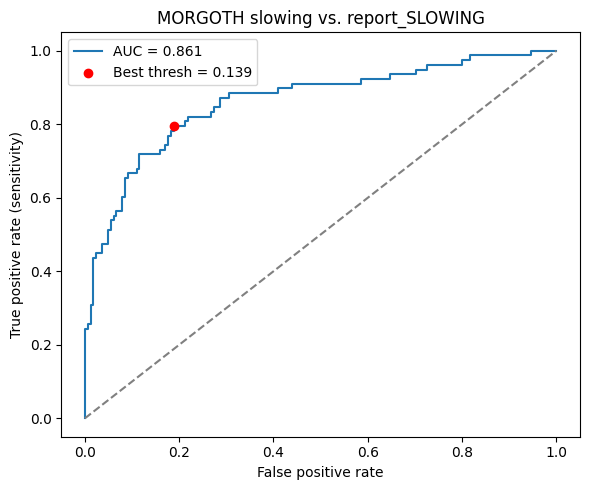

AUROC          : 0.861
Best threshold : 0.1387  (Youden's J = 0.606)


In [6]:
y_true  = merged["label"].values
y_score = merged["fraction_slowing"].values

auc = roc_auc_score(y_true, y_score)
fpr, tpr, thresholds = roc_curve(y_true, y_score)

# Youden's J: maximise sensitivity + specificity
j         = tpr - fpr
best_idx  = np.argmax(j)
best_thr  = thresholds[best_idx]

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax.scatter(fpr[best_idx], tpr[best_idx], color="red", zorder=5,
           label=f"Best thresh = {best_thr:.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("MORGOTH slowing vs. report_SLOWING")
ax.legend()
plt.tight_layout()
plt.show()
print(f"AUROC          : {auc:.3f}")
print(f"Best threshold : {best_thr:.4f}  (Youden's J = {j[best_idx]:.3f})")

## 5. Accuracy and confusion matrix at best threshold

Threshold   : 0.1387
Accuracy    : 0.806
Sensitivity : 0.795
Specificity : 0.811

              precision    recall  f1-score   support

      absent       0.89      0.81      0.85       164
     present       0.67      0.79      0.73        78

    accuracy                           0.81       242
   macro avg       0.78      0.80      0.79       242
weighted avg       0.82      0.81      0.81       242



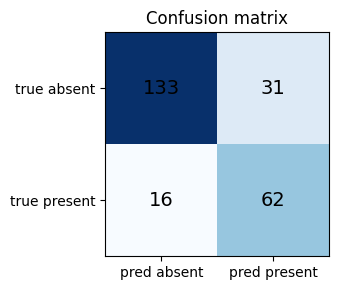

In [7]:
y_pred = (y_score >= best_thr).astype(int)

acc = accuracy_score(y_true, y_pred)
cm  = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Threshold   : {best_thr:.4f}")
print(f"Accuracy    : {acc:.3f}")
print(f"Sensitivity : {tp / (tp + fn):.3f}")
print(f"Specificity : {tn / (tn + fp):.3f}")
print()
print(classification_report(y_true, y_pred, target_names=["absent", "present"]))

fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1]); ax.set_xticklabels(["pred absent", "pred present"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["true absent", "true present"])
ax.set_title("Confusion matrix")
plt.tight_layout()
plt.show()

## 6. Accuracy at several fixed thresholds

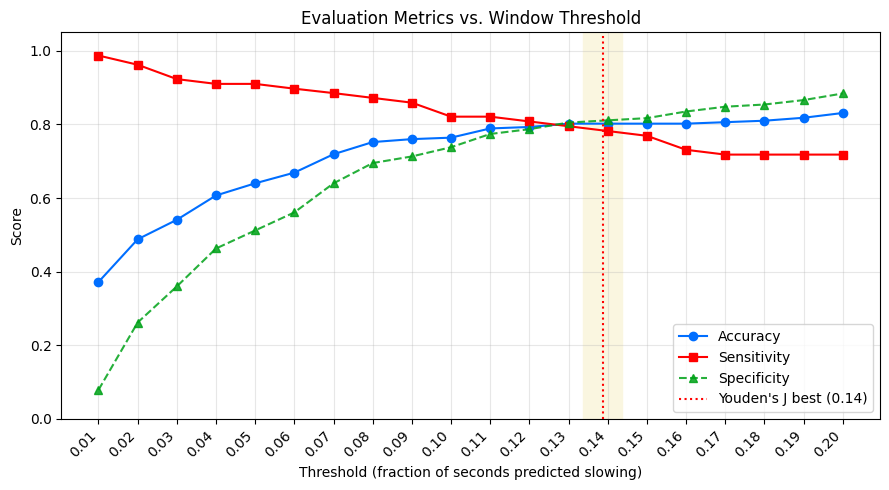

,threshold,accuracy,sensitivity,specificity
0,0.01,0.372,0.987,0.079
1,0.02,0.488,0.962,0.262
2,0.03,0.541,0.923,0.360
3,0.04,0.607,0.910,0.463
4,0.05,0.640,0.910,0.512
5,0.06,0.669,0.897,0.561
6,0.07,0.719,0.885,0.640
7,0.08,0.752,0.872,0.695
8,0.09,0.760,0.859,0.713
9,0.10,0.764,0.821,0.738


In [13]:
thresholds_sweep = np.round(np.arange(0.01, 0.21, 0.01), 2)

rows_out = []
for thr in thresholds_sweep:
    yp = (y_score >= thr).astype(int)
    _cm = confusion_matrix(y_true, yp)
    _tn, _fp, _fn, _tp = _cm.ravel()
    rows_out.append({
        "threshold":   thr,
        "accuracy":    accuracy_score(y_true, yp),
        "sensitivity": _tp / (_tp + _fn),
        "specificity": _tn / (_tn + _fp),
    })

df_sweep = pd.DataFrame(rows_out).round(3)

C_ACC  = "#006EFF"   # blue
C_SENS = "#FF0000"   # dark crimson
C_SPEC = "#00A218"   # green

fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(best_thr - 0.005, best_thr + 0.005, color="#FAF6E0", zorder=0)
ax.plot(df_sweep["threshold"], df_sweep["accuracy"],    marker="o", color=C_ACC,  label="Accuracy")
ax.plot(df_sweep["threshold"], df_sweep["sensitivity"], marker="s", color=C_SENS, label="Sensitivity")
ax.plot(df_sweep["threshold"], df_sweep["specificity"], marker="^", color=C_SPEC, linestyle="--", alpha=0.85, label="Specificity")
ax.axvline(best_thr, color="red", linestyle=":", linewidth=1.5,
           label=f"Youden's J best ({best_thr:.2f})")
ax.set_xlabel("Threshold (fraction of seconds predicted slowing)")
ax.set_ylabel("Score")
ax.set_title("Evaluation Metrics vs. Window Threshold")
ax.set_xticks(thresholds_sweep)
ax.set_xticklabels([f"{t:.2f}" for t in thresholds_sweep], rotation=45, ha="right")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

df_sweep